In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


### Exploratory Data Analysis (EDA)

In [2]:
df = pd.read_csv("FastFoodNutritionMenuV2.csv") # loads the dataset
df.head()

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
0,McDonald’s,Hamburger,250,80,9,3.5,0.5,25,520,31,2,6,12,247.5
1,McDonald’s,Cheeseburger,300,110,12,6,0.5,40,750,33,2,6,15,297
2,McDonald’s,Double Cheeseburger,440,210,23,11,1.5,80,1150,34,2,7,25,433
3,McDonald’s,McDouble,390,170,19,8,1,65,920,33,2,7,22,383
4,McDonald’s,Quarter Pounder® with Cheese,510,230,26,12,1.5,90,1190,40,3,9,29,502


In [3]:
df = df.rename(columns={  #r enames all of the columns, making them easier to write and more consistent
    "Total Fat\n(g)": "Total_Fat_g",
    "Saturated Fat\n(g)": "Saturated_Fat_g",
    "Trans Fat\n(g)": "Trans_Fat_g",
    "Cholesterol\n(mg)": "Cholesterol_mg",
    "Sodium \n(mg)": "Sodium_mg",
    "Carbs\n(g)": "Carbs_g",
    "Fiber\n(g)": "Fiber_g",
    "Sugars\n(g)": "Sugars_g",
    "Protein\n(g)": "Protein_g",
})

df["Calories"] = pd.to_numeric(df["Calories"], errors="coerce")   # converts all of the categories into the numeric data type
df["Total_Fat_g"] = pd.to_numeric(df["Total_Fat_g"], errors="coerce")
df["Saturated_Fat_g"] = pd.to_numeric(df["Saturated_Fat_g"], errors="coerce")
df["Trans_Fat_g"] = pd.to_numeric(df["Trans_Fat_g"], errors="coerce")
df["Cholesterol_mg"] = pd.to_numeric(df["Cholesterol_mg"], errors="coerce")
df["Sodium_mg"] = pd.to_numeric(df["Sodium_mg"], errors="coerce")
df["Carbs_g"] = pd.to_numeric(df["Carbs_g"], errors="coerce")
df["Fiber_g"] = pd.to_numeric(df["Fiber_g"], errors="coerce")
df["Sugars_g"] = pd.to_numeric(df["Sugars_g"], errors="coerce")
df["Protein_g"] = pd.to_numeric(df["Protein_g"], errors="coerce")

In [4]:
print("Dataset shape:", df.shape)      
print("\nColumn names:")
print(df.columns)      # prints the shape of the data set

print("\nMissing values per column:") 
print(df.isnull().sum()) # prints the amount of missing values in the column

Dataset shape: (1148, 14)

Column names:
Index(['Company', 'Item', 'Calories', 'Calories from\nFat', 'Total_Fat_g',
       'Saturated_Fat_g', 'Trans_Fat_g', 'Cholesterol_mg', 'Sodium_mg',
       'Carbs_g', 'Fiber_g', 'Sugars_g', 'Protein_g', 'Weight Watchers\nPnts'],
      dtype='object')

Missing values per column:
Company                    0
Item                       0
Calories                  15
Calories from\nFat       506
Total_Fat_g               69
Saturated_Fat_g           70
Trans_Fat_g               69
Cholesterol_mg            29
Sodium_mg                 16
Carbs_g                   70
Fiber_g                   84
Sugars_g                  30
Protein_g                 69
Weight Watchers\nPnts    261
dtype: int64


In [5]:
df.describe() # gives statistics about the dataset

,Calories,Total_Fat_g,Saturated_Fat_g,Trans_Fat_g,Cholesterol_mg,Sodium_mg,Carbs_g,Fiber_g,Sugars_g,Protein_g
count,1133.000000,1079.000000,1078.000000,1079.000000,1119.000000,1132.000000,1078.000000,1064.000000,1118.000000,1079.000000
mean,287.356575,11.682576,4.066790,0.140871,40.647900,427.722615,38.946197,1.454887,24.067979,9.434662
std,222.135591,13.957331,5.027242,0.489773,68.058662,496.701818,31.654807,2.389581,32.369327,11.049859
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,140.000000,0.000000,0.000000,0.000000,0.000000,70.000000,17.000000,0.000000,2.000000,0.000000
50%,240.000000,8.000000,3.000000,0.000000,20.000000,190.000000,34.000000,0.000000,8.000000,7.000000
75%,390.000000,18.000000,6.000000,0.000000,50.000000,680.000000,52.000000,2.000000,40.000000,14.000000
max,1220.000000,98.000000,33.000000,4.500000,575.000000,2890.000000,270.000000,31.000000,264.000000,71.000000


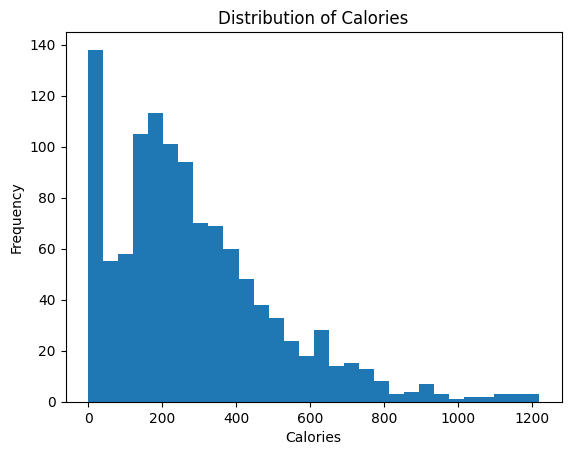

In [6]:
plt.figure()
plt.hist(df["Calories"], bins=30)
plt.xlabel("Calories")
plt.ylabel("Frequency")
plt.title("Distribution of Calories")
plt.show() # displays the histogram

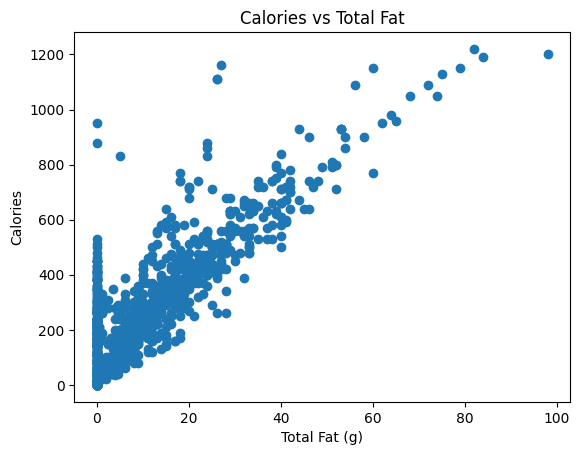

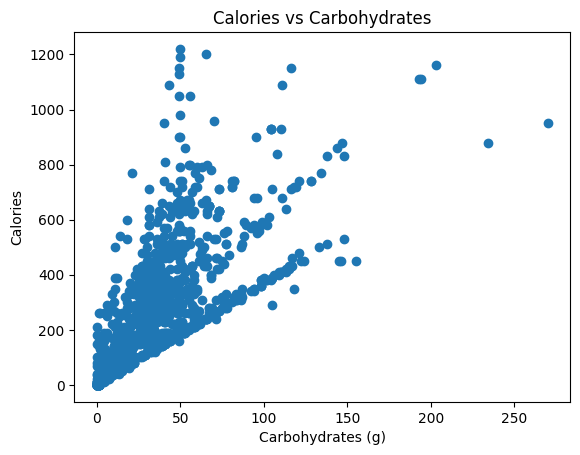

In [7]:
plt.figure()
plt.scatter(df["Total_Fat_g"], df["Calories"])
plt.xlabel("Total Fat (g)")
plt.ylabel("Calories")
plt.title("Calories vs Total Fat")
plt.show()  # creates a scatter plot comparing Total Fat to Calories

plt.figure()
plt.scatter(df["Carbs_g"], df["Calories"])
plt.xlabel("Carbohydrates (g)")
plt.ylabel("Calories")
plt.title("Calories vs Carbohydrates")
plt.show() # creates a scatterplot comparing Carbs to Calories

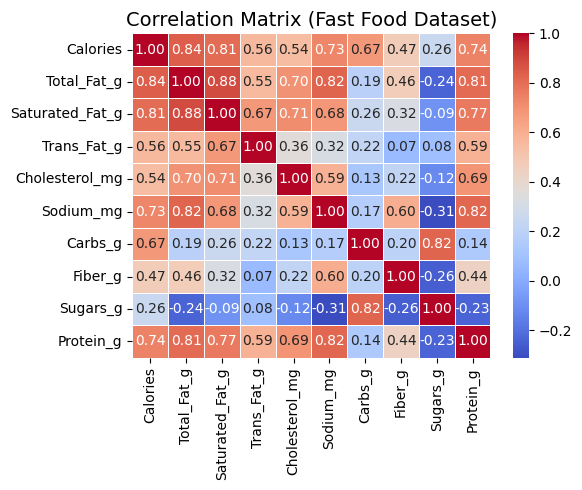

In [8]:
# Compute correlation matrix
corr = df.corr(numeric_only=True)

# Plots the heatmap
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix (Fast Food Dataset)", fontsize=14)
plt.tight_layout()
plt.show()

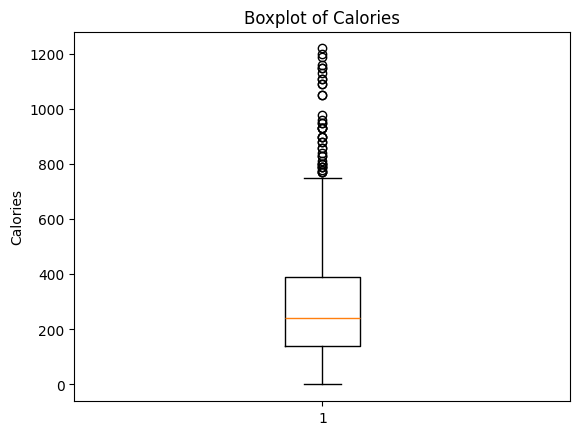

In [9]:
df["Calories"] = pd.to_numeric(df["Calories"], errors="coerce")
plt.figure()
plt.boxplot(df["Calories"].dropna().values)
plt.ylabel("Calories")
plt.title("Boxplot of Calories")
plt.show()   # creates a boxplot of calories, dropping null entries.

### Data Preparation

In [10]:
# drops the categories not relevant to the amount of calories an item would have
df = df.drop(columns=["Calories from\nFat", "Weight Watchers\nPnts", "Company", "Item"]) 

df = df[df["Calories"] > 0] # removes entries with zeroes for calories


Train Test/Split

In [11]:
y = df["Calories"]
X = df.drop(columns=["Calories"])   # X variable is all columns besides Calories

X = X.apply(pd.to_numeric, errors="coerce")
data = pd.concat([X, y], axis=1).dropna()
X = data.drop(columns=["Calories"])
y = data["Calories"]

# Test split (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Validation split (15% of the remaining)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15, random_state=42
)

scaler = StandardScaler()  # data processing technique to scale the data, used for specific models
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("Number of features:", X_train.shape[1])

Train: (696, 9) Val: (123, 9) Test: (145, 9)
Number of features: 9


### Model Training

Linear Regression

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

model = LinearRegression()

# Linear Regression model (no feature scaling required)
model.fit(X_train, y_train)

# Generate Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_val_pred = model.predict(X_val)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

###### You will see that we created two rmse's and r2s for all performances (seemingly redundant) but this just for less typing and is used later on for model comparison ######
lr_train_rmse = root_mean_squared_error(y_train, y_train_pred)
lr_train_r2 = r2_score(y_train, y_train_pred)

print(' ***   Training Performance   ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²: {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

lr_test_rmse = root_mean_squared_error(y_test, y_test_pred)
lr_test_r2 = r2_score(y_test, y_test_pred)

print(' ***   Testing Performance   ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²: {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

lr_val_rmse = root_mean_squared_error(y_val, y_val_pred)
lr_val_r2 = r2_score(y_val, y_val_pred)

print('*** Validation Performance (Linear Regression) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²:   {val_r2:.3f}")

 ***   Training Performance   ***
RMSE: 12.305
R²: 0.997
 ***   Testing Performance   ***
RMSE: 12.082
R²: 0.997
*** Validation Performance (Linear Regression) ***
RMSE: 13.793
R²:   0.996


Non-linear/Polynomial Regression

In [13]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

poly = PolynomialFeatures(degree=2, include_bias=False) 

# Fit polynomial transformation
X_train_poly = poly.fit_transform(X_train)   
X_val_poly = poly.transform(X_val)
X_test_poly = poly.transform(X_test)


# Polynomial Regression model (scaling not required)
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

# Generate Predictions
y_train_pred = model_poly.predict(X_train_poly)
y_val_pred = model_poly.predict(X_val_poly)
y_test_pred = model_poly.predict(X_test_poly)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

poly_train_rmse = root_mean_squared_error(y_train, y_train_pred)
poly_train_r2 = r2_score(y_train, y_train_pred)

print('*** Training Performance (Polynomial Regression, deg=2) ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²:   {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

poly_test_rmse = root_mean_squared_error(y_test, y_test_pred)
poly_test_r2 = r2_score(y_test, y_test_pred)

print('*** Testing Performance (Polynomial Regression, deg=2) ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²:   {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

poly_val_rmse = root_mean_squared_error(y_val, y_val_pred)
poly_val_r2 = r2_score(y_val, y_val_pred)

print('*** Validation Performance (Polynomial Regression, deg=2) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²:   {val_r2:.3f}")

*** Training Performance (Polynomial Regression, deg=2) ***
RMSE: 10.302
R²:   0.998
*** Testing Performance (Polynomial Regression, deg=2) ***
RMSE: 10.034
R²:   0.998
*** Validation Performance (Polynomial Regression, deg=2) ***
RMSE: 11.623
R²:   0.997


KNN Regression

In [14]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

# KNN Regression Model(scaling required)
k = 5  
knn_model = KNeighborsRegressor(n_neighbors=k)
knn_model.fit(X_train_scaled, y_train)

# Generate Predictions
y_train_pred = knn_model.predict(X_train_scaled)
y_val_pred = knn_model.predict(X_val_scaled)
y_test_pred = knn_model.predict(X_test_scaled)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

knn_train_rmse = root_mean_squared_error(y_train, y_train_pred)
knn_train_r2 = r2_score(y_train, y_train_pred)

print(f'*** Training Performance (KNN Regression, k={k}) ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²:   {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

knn_test_rmse = root_mean_squared_error(y_test, y_test_pred)
knn_test_r2 = r2_score(y_test, y_test_pred)

print(f'*** Testing Performance (KNN Regression, k={k}) ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²:   {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

knn_val_rmse = root_mean_squared_error(y_val, y_val_pred)
knn_val_r2 = r2_score(y_val, y_val_pred)

print(f'*** Validation Performance (KNN Regression, k={k}) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²:   {val_r2:.3f}")

*** Training Performance (KNN Regression, k=5) ***
RMSE: 38.084
R²:   0.969
*** Testing Performance (KNN Regression, k=5) ***
RMSE: 42.015
R²:   0.963
*** Validation Performance (KNN Regression, k=5) ***
RMSE: 58.848
R²:   0.935


Support Vector Regression (SVR)

In [15]:
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, r2_score

# SVR Model (scaling required)
svr_model = SVR(kernel='rbf')  # using an rbf kernel
svr_model.fit(X_train_scaled, y_train)

# Generate Predictions
y_train_pred = svr_model.predict(X_train_scaled)
y_val_pred = svr_model.predict(X_val_scaled)
y_test_pred = svr_model.predict(X_test_scaled)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

svr_train_rmse = root_mean_squared_error(y_train, y_train_pred)
svr_train_r2 = r2_score(y_train, y_train_pred)

print('*** Training Performance (SVR) ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²:   {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

svr_test_rmse = root_mean_squared_error(y_test, y_test_pred)
svr_test_r2 = r2_score(y_test, y_test_pred)

print('*** Testing Performance (SVR) ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²:   {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

svr_val_rmse = root_mean_squared_error(y_val, y_val_pred)
svr_val_r2 = r2_score(y_val, y_val_pred)

print('*** Validation Performance (SVR) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²:   {val_r2:.3f}")

*** Training Performance (SVR) ***
RMSE: 161.796
R²:   0.444
*** Testing Performance (SVR) ***
RMSE: 171.062
R²:   0.392
*** Validation Performance (SVR) ***
RMSE: 177.330
R²:   0.411


Decision Tree Regression

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
import numpy as np

# define the minimum samples per leaf
candidates = [1, 2, 5, 10, 15, 20, 25, 50, 100]
results = []

best_val = -np.inf
best_leaf = None

for msl in candidates:
    tree_reg = DecisionTreeRegressor(min_samples_leaf=msl, random_state=42)  # finds the best minimum samples per leaf
    tree_reg.fit(X_train, y_train)
    y_pred_val = tree_reg.predict(X_val)
    
    r2_val = r2_score(y_val, y_pred_val)
    results.append(r2_val)

    print(f"min_samples_leaf = {msl}| R2_val = {r2_val:.3f}")
    
    if r2_val > best_val:
        best_val = r2_val
        best_leaf = msl

best_msl = candidates[np.argmax(results)]
print(f"Best minimum samples per leaf (by validation): {best_msl}\n")


# Decision Tree Regression Model (scaling not required)
tree_reg = DecisionTreeRegressor(random_state=42, min_samples_leaf=best_msl)
tree_reg.fit(X_train, y_train)

# Generate Predictions
y_train_pred = tree_reg.predict(X_train)
y_val_pred = tree_reg.predict(X_val)
y_test_pred = tree_reg.predict(X_test)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

tree_train_rmse = root_mean_squared_error(y_train, y_train_pred)
tree_train_r2 = r2_score(y_train, y_train_pred)

print('*** Training Performance (Decision Tree) ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²: {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

tree_test_rmse = root_mean_squared_error(y_test, y_test_pred)
tree_test_r2 = r2_score(y_test, y_test_pred)

print('*** Testing Performance (Decision Tree) ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²: {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

tree_val_rmse = root_mean_squared_error(y_val, y_val_pred)
tree_val_r2 = r2_score(y_val, y_val_pred)

print('*** Validation Performance (Decision Tree) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²: {val_r2:.3f}")



min_samples_leaf = 1| R2_val = 0.959
min_samples_leaf = 2| R2_val = 0.967
min_samples_leaf = 5| R2_val = 0.955
min_samples_leaf = 10| R2_val = 0.908
min_samples_leaf = 15| R2_val = 0.903
min_samples_leaf = 20| R2_val = 0.876
min_samples_leaf = 25| R2_val = 0.836
min_samples_leaf = 50| R2_val = 0.778
min_samples_leaf = 100| R2_val = 0.661
Best minimum samples per leaf (by validation): 2

*** Training Performance (Decision Tree) ***
RMSE: 12.830
R²: 0.997
*** Testing Performance (Decision Tree) ***
RMSE: 44.116
R²: 0.960
*** Validation Performance (Decision Tree) ***
RMSE: 42.053
R²: 0.967


Random Forest Regression

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

# define tree depths
candidates = [5, 10, 50, 100, 500]

results = []

for nbr in candidates: # find best numbers of estimators
    model = RandomForestRegressor(n_estimators=nbr, max_depth=None, random_state=42)
    model.fit(X_train, y_train)
    y_pred_val = model.predict(X_val)
    r2 = r2_score(y_pred_val, y_val)
    results.append(r2)
    print(f"n_estimators={nbr} → R2_score: {r2:.3f}")

best_nbr = candidates[np.argmax(results)]
print(f"Best number of estimators (by validation): {best_nbr}\n")

# Random Forest Regression Model (scaling not required)
RF_reg = RandomForestRegressor(n_estimators=best_nbr, max_depth=None, random_state=42)
RF_reg.fit(X_train, y_train)

# Training Performance
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

rf_train_rmse = root_mean_squared_error(y_train, y_train_pred)
rf_train_r2 = r2_score(y_train, y_train_pred)

print('*** Training Performance (Random Forest) ***')
print(f"RMSE: {train_rmse:.3f}")
print(f"R²: {train_r2:.3f}")

# Testing Performance
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

rf_test_rmse = root_mean_squared_error(y_test, y_test_pred)
rf_test_r2 = r2_score(y_test, y_test_pred)

print('*** Testing Performance (Random Forest) ***')
print(f"RMSE: {test_rmse:.3f}")
print(f"R²: {test_r2:.3f}")

# Validation Performance
val_rmse = root_mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

rf_val_rmse = root_mean_squared_error(y_val, y_val_pred)
rf_val_r2 = r2_score(y_val, y_val_pred)

print('*** Validation Performance (Random Forest) ***')
print(f"RMSE: {val_rmse:.3f}")
print(f"R²: {val_r2:.3f}")

n_estimators=5 → R2_score: 0.976
n_estimators=10 → R2_score: 0.982
n_estimators=50 → R2_score: 0.983
n_estimators=100 → R2_score: 0.983
n_estimators=500 → R2_score: 0.983
Best number of estimators (by validation): 100

*** Training Performance (Random Forest) ***
RMSE: 12.830
R²: 0.997
*** Testing Performance (Random Forest) ***
RMSE: 44.116
R²: 0.960
*** Validation Performance (Random Forest) ***
RMSE: 42.053
R²: 0.967


### Model Evaluation

In [18]:
import pandas as pd

# Build table of training performances
train_table = pd.DataFrame({
    "Model": ["Linear Regression",
              "Polynomial Regression",
              "KNN Regression",
              "SVR",
              "Decision Tree",
              "Random Forest"],
    "RMSE": [lr_train_rmse,
             poly_train_rmse,  
             knn_train_rmse,
             svr_train_rmse,
             tree_train_rmse,
             rf_train_rmse],
    "R2": [lr_train_r2,
           poly_train_r2,
           knn_train_r2,
           svr_train_r2,
           tree_train_r2,
           rf_train_r2]})


print("Training Performances for All Models")
display(train_table)

Training Performances for All Models


,Model,RMSE,R2
0,Linear Regression,12.305043,0.996785
1,Polynomial Regression,10.302455,0.997746
2,KNN Regression,38.084280,0.969202
3,SVR,161.796496,0.444136
4,Decision Tree,12.829704,0.996505
5,Random Forest,12.829704,0.996505


In [19]:
# Build table of validation performances
val_table = pd.DataFrame({
    "Model": ["Linear Regression",
              "Polynomial Regression",
              "KNN Regression",
              "SVR",
              "Decision Tree",
             "Random Forest"],
    "RMSE": [lr_val_rmse,
             poly_val_rmse,
             knn_val_rmse,
             svr_val_rmse,
             tree_val_rmse,
             rf_val_rmse],
    "R2": [lr_val_r2,
           poly_val_r2,
           knn_val_r2,
           svr_val_r2,
           tree_val_r2,
           rf_val_r2]})


print("Validation Performances for All Models")
display(val_table)


Validation Performances for All Models


,Model,RMSE,R2
0,Linear Regression,13.793413,0.996437
1,Polynomial Regression,11.622651,0.997470
2,KNN Regression,58.847536,0.935146
3,SVR,177.330464,0.411091
4,Decision Tree,42.052549,0.966882
5,Random Forest,42.052549,0.966882


As seen with the tables above, Polynomial Regression, Linear Regression, and Decision Tree Regression are the top 3 models based on validation performances

In [20]:
# Build table of testing performances for only the top 3 models
test_table_top3 = pd.DataFrame({   
    "Model": ["Polynomial Regression",
              "Linear Regression",
              "Decision Tree",],
    "RMSE": [poly_val_rmse,
             lr_val_rmse,
             tree_val_rmse,],
    "R2": [poly_val_r2,
           lr_val_r2,
           tree_val_r2,]})

print("Validation Performances for Top 3 Models")
display(test_table_top3)

Validation Performances for Top 3 Models


,Model,RMSE,R2
0,Polynomial Regression,11.622651,0.997470
1,Linear Regression,13.793413,0.996437
2,Decision Tree,42.052549,0.966882


### Model Prediction and Interpretation

Non-Linear/Polynomial Regression

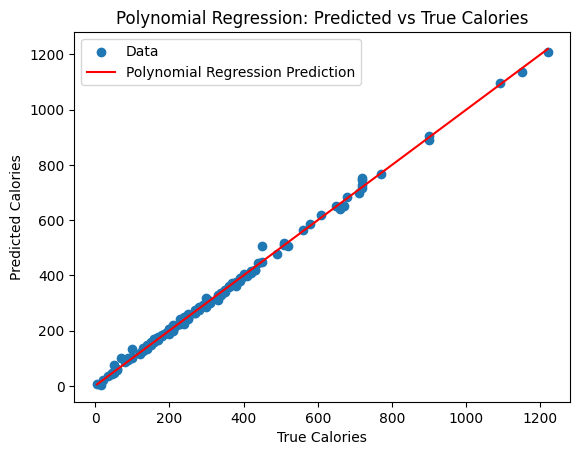

In [21]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

# Redefine and train model to reset variables
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)
X_test_poly = poly.transform(X_test)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

y_train_pred = model_poly.predict(X_train_poly)
y_val_pred = model_poly.predict(X_val_poly)
y_test_pred = model_poly.predict(X_test_poly)

# Create visual for the regression model
plt.figure()

plt.scatter(y_test, y_test_pred, label='Data')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', label="Polynomial Regression Prediction")
plt.legend()

plt.xlabel("True Calories")
plt.ylabel("Predicted Calories")
plt.title("Polynomial Regression: Predicted vs True Calories")
plt.show()



Linear Regression

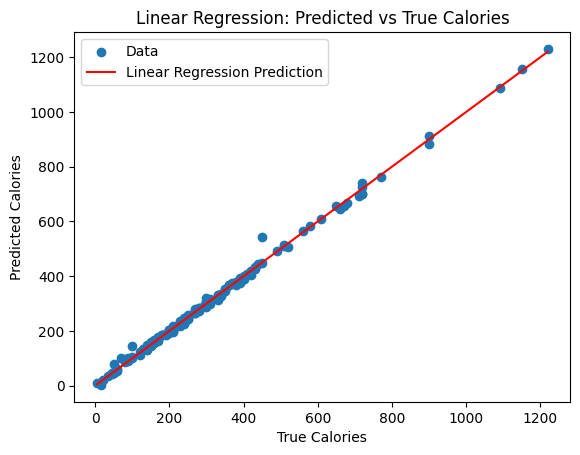

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

# Redefine and train model to reset variables
model = LinearRegression()

# Linear Regression model (no feature scaling required)
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_val_pred = model.predict(X_val)

# Create visual for the regression model
plt.figure()
plt.scatter(y_test, y_test_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', label="Linear Regression Prediction")
plt.legend()

plt.xlabel("True Calories")
plt.ylabel("Predicted Calories")
plt.title("Linear Regression: Predicted vs True Calories")
plt.show()



Decision Tree Regression

min_samples_leaf = 1| R2_val = 0.959
min_samples_leaf = 2| R2_val = 0.967
min_samples_leaf = 5| R2_val = 0.955
min_samples_leaf = 10| R2_val = 0.908
min_samples_leaf = 15| R2_val = 0.903
min_samples_leaf = 20| R2_val = 0.876
min_samples_leaf = 25| R2_val = 0.836
min_samples_leaf = 50| R2_val = 0.778
min_samples_leaf = 100| R2_val = 0.661
Best minimum samples per leaf (by validation): 2



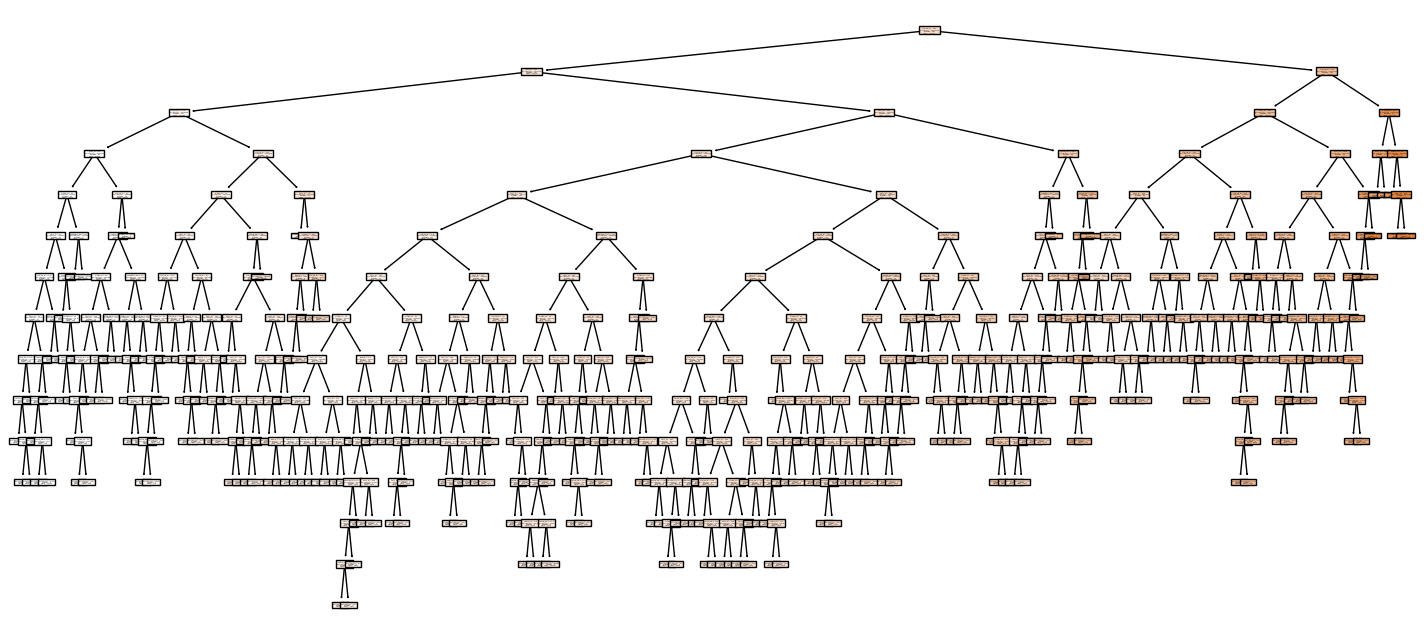

In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn import tree
import numpy as np

# Redefine and train model to reset variables
# define the minimum samples per leaf
candidates = [1, 2, 5, 10, 15, 20, 25, 50, 100]
results = []

best_val = -np.inf
best_leaf = None

for msl in candidates:
    tree_reg = DecisionTreeRegressor(min_samples_leaf=msl, random_state=42)
    tree_reg.fit(X_train, y_train)
    y_pred_val = tree_reg.predict(X_val)
    
    r2_val = r2_score(y_val, y_pred_val)
    results.append(r2_val)

    print(f"min_samples_leaf = {msl}| R2_val = {r2_val:.3f}")
    
    if r2_val > best_val:
        best_val = r2_val
        best_leaf = msl

best_msl = candidates[np.argmax(results)]
print(f"Best minimum samples per leaf (by validation): {best_msl}\n")


# Train Model
tree_reg = DecisionTreeRegressor(random_state=42, min_samples_leaf=best_msl)
tree_reg.fit(X_train, y_train)

y_train_pred = tree_reg.predict(X_train)
y_val_pred = tree_reg.predict(X_val)
y_test_pred = tree_reg.predict(X_test)

# Plot the decision tree
plt.figure(figsize=(18,8))
tree.plot_tree(tree_reg, filled=True, feature_names=X.columns)
plt.show()